# PS- 2B: CNN for Handwritten MNIST Classification

Open this notebook with `PS- 2B` as the working folder and run the cells from top to bottom using a Python 3 kernel with TensorFlow, pandas, and matplotlib installed. Both CSV files are loaded from this folder only.

Each row contains a digit label and 784 pixels. Reshape the pixels to 28 x 28 x 1 for the CNN. The separate test CSV is used only to estimate the final performance.


In [1]:
# Import all necessary packages first
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam


In [2]:
# a. Load and preprocess the image data
train = pd.read_csv("mnist_train.csv")
test = pd.read_csv("mnist_test.csv")

# Scale pixels to 0-1 and reshape each image to 28 x 28 x 1.
x_train = train.drop("label", axis=1).values.astype("float32") / 255.0
x_test = test.drop("label", axis=1).values.astype("float32") / 255.0
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)
y_train = train["label"].values
y_test = test["label"].values


In [ ]:
# Show 10 training images in a 2 x 5 subplot.
image_labels = y_train[:10]
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {image_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [3]:
# b. Define the model's architecture
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# c. Train the model
model.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
# Use 10% of the training data for validation.
history = model.fit(x_train, y_train, epochs=10, batch_size=64,
                    validation_split=0.1, verbose=2)


Epoch 1/10
844/844 - 38s - 45ms/step - accuracy: 0.9441 - loss: 0.1874 - val_accuracy: 0.9828 - val_loss: 0.0606
Epoch 2/10
844/844 - 28s - 33ms/step - accuracy: 0.9831 - loss: 0.0549 - val_accuracy: 0.9873 - val_loss: 0.0482
Epoch 3/10
844/844 - 28s - 33ms/step - accuracy: 0.9883 - loss: 0.0378 - val_accuracy: 0.9872 - val_loss: 0.0418
Epoch 4/10
844/844 - 29s - 35ms/step - accuracy: 0.9916 - loss: 0.0280 - val_accuracy: 0.9878 - val_loss: 0.0431
Epoch 5/10
844/844 - 22s - 26ms/step - accuracy: 0.9925 - loss: 0.0228 - val_accuracy: 0.9897 - val_loss: 0.0338
Epoch 6/10
844/844 - 27s - 32ms/step - accuracy: 0.9943 - loss: 0.0173 - val_accuracy: 0.9903 - val_loss: 0.0359
Epoch 7/10
844/844 - 26s - 30ms/step - accuracy: 0.9956 - loss: 0.0144 - val_accuracy: 0.9907 - val_loss: 0.0421
Epoch 8/10
844/844 - 24s - 29ms/step - accuracy: 0.9958 - loss: 0.0119 - val_accuracy: 0.9900 - val_loss: 0.0402
Epoch 9/10
844/844 - 26s - 31ms/step - accuracy: 0.9968 - loss: 0.0101 - val_accuracy: 0.9892 - 

Test loss: 0.0381
Test accuracy: 98.94%


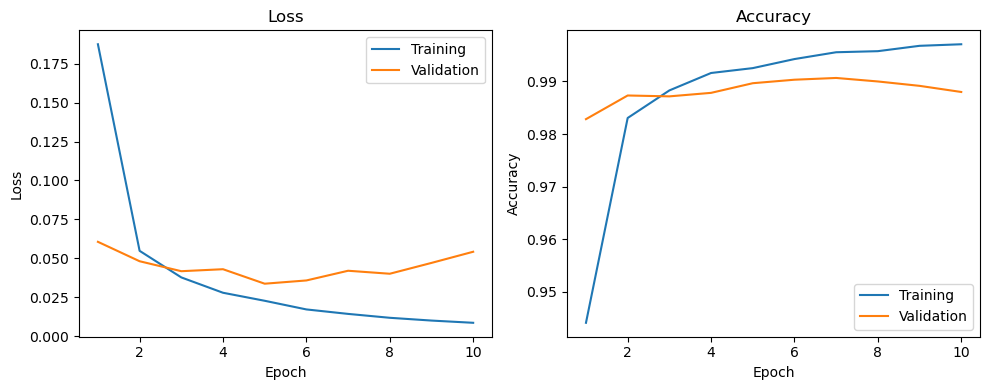

In [5]:
# d. Estimate the model's performance on the separate test data
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

epochs = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["loss"], label="Training")
plt.plot(epochs, history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["accuracy"], label="Training")
plt.plot(epochs, history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# Show 10 test images with actual and predicted labels after training.
predicted_labels = model.predict(x_test[:10], verbose=0).argmax(axis=1)
actual_labels = y_test[:10]

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Actual: {actual_labels[i]}\nPredicted: {predicted_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()
